In [11]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

from src.environments.shuttleenvironment import (
    ShuttleEnvironment,
    ShuttleEnvironmentAction,
)
from src.solvers.shuttlepolicyiteration import ShuttlePolicyIteration
from src.solvers.shuttlevalueiteration import ShuttleValueIteration

In [12]:
SHUTTLE_CAPACITY = 15  # The capacity of the shuttle if diepatched (K)
SHUTTLE_DISPATCH_COST = 100  # The cost of dispatching a shuttle (c_f)
CUSTOMER_WAITING_COST = 2  # The cost per customer left waiting per time period (c_h)
CUSTOMER_ARRIVING_OPTIONS = [
    1,
    2,
    3,
    4,
    5,
]  # RV of number of customers arriving during time interval (A_t)
CUSTOMER_ARRIVING_PROBABILITIES = [
    1 / 5,
    1 / 5,
    1 / 5,
    1 / 5,
    1 / 5,
]  # Probs. of the RV for number of customers arriving during time interval (A_t)
GAMMA = 0.95  # Discount Factor
MAX_STATE = 200  # Number of people in station cannot exceed 200
THETA = 1e-6  # Convergence Tolearnce

In [13]:
shuttle_env = ShuttleEnvironment(
    shuttle_capacity=SHUTTLE_CAPACITY,
    shuttle_dispatch_cost=SHUTTLE_DISPATCH_COST,
    customer_waiting_cost=CUSTOMER_WAITING_COST,
    customer_arriving_options=CUSTOMER_ARRIVING_OPTIONS,
    customer_arriving_probabilities=CUSTOMER_ARRIVING_PROBABILITIES,
)

In [14]:
pi_solver = ShuttlePolicyIteration(
    env=shuttle_env, max_state=MAX_STATE, gamma=GAMMA, theta=THETA
)
pi_solver.solve()

print(
    f"Converged after {len(pi_solver.policy_history)} policy evaluations "
    f"({sum(pi_solver.evaluation_sweeps)} evaluation sweeps in total)"
)

Converged after 6 policy evaluations (1930 evaluation sweeps in total)


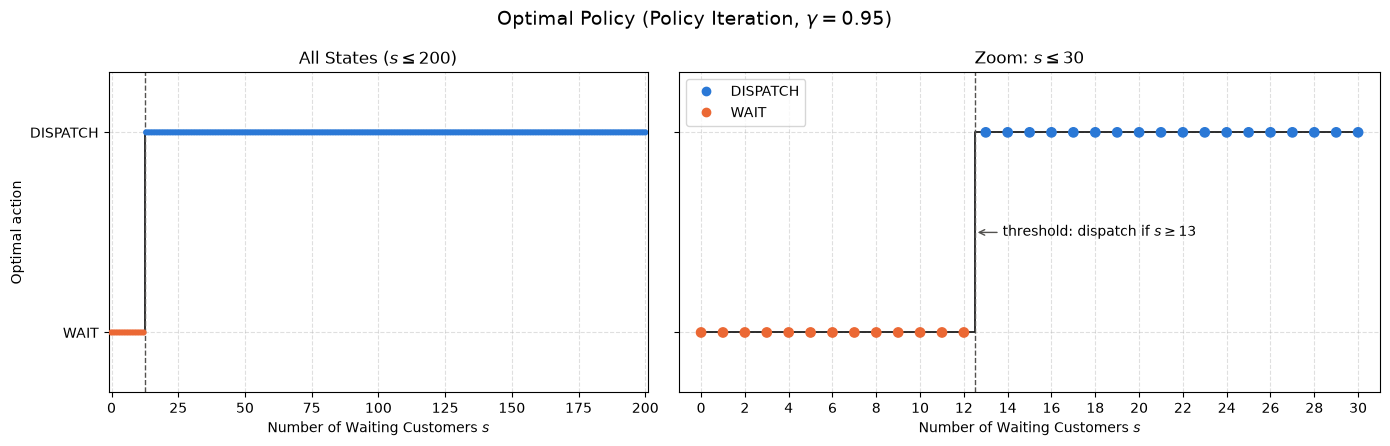

In [15]:
BLUE, ORANGE, AQUA, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e"
ZOOM_STATE = 30

states = np.arange(MAX_STATE + 1)
dispatch = np.array(
    [pi_solver.get_action(s) == ShuttleEnvironmentAction.DISPATCH for s in states]
)
threshold = int(np.argmax(dispatch))  # First state in which dispatching is optimal

fig, (ax_full, ax_zoom) = plt.subplots(
    1, 2, figsize=(14, 4.5), width_ratios=(1, 1.3), sharey=True
)

for ax, shown in ((ax_full, states), (ax_zoom, states[: ZOOM_STATE + 1])):
    ax.step(shown, dispatch[shown].astype(int), where="mid", color=INK, linewidth=1.2)
    ax.scatter(
        shown,
        dispatch[shown].astype(int),
        color=np.where(dispatch[shown], BLUE, ORANGE),
        s=12 if ax is ax_full else 45,
        zorder=3,
    )
    ax.axvline(threshold - 0.5, linestyle="--", color=MUTED, linewidth=1)
    ax.set(xlabel="Number of Waiting Customers $s$", xlim=(-1, shown[-1] + 1))
    ax.grid(True, linestyle="--", alpha=0.4)

ax_full.set(
    title=f"All States ($s \\leq {MAX_STATE}$)",
    ylabel="Optimal action",
    yticks=[0, 1],
    yticklabels=["WAIT", "DISPATCH"],
    ylim=(-0.3, 1.3),
)
ax_zoom.set(title=f"Zoom: $s \\leq {ZOOM_STATE}$", xticks=range(0, ZOOM_STATE + 1, 2))
ax_zoom.annotate(
    f"threshold: dispatch if $s \\geq {threshold}$",
    (threshold - 0.5, 0.5),
    xytext=(20, 0),
    textcoords="offset points",
    va="center",
    arrowprops=dict(arrowstyle="->", color=MUTED),
)
ax_zoom.legend(
    handles=[
        plt.Line2D([], [], marker="o", linestyle="", color=BLUE, label="DISPATCH"),
        plt.Line2D([], [], marker="o", linestyle="", color=ORANGE, label="WAIT"),
    ],
    loc="upper left",
)
fig.suptitle(f"Optimal Policy (Policy Iteration, $\\gamma = {GAMMA}$)", fontsize=14)
fig.tight_layout()
plt.show()

## Checks
The cell below defines small helpers and solves the same problem with value iteration (2b) as a reference.

In [ ]:
def report(name: str, passed: bool) -> None:
    print(f"[{'PASS' if passed else 'FAIL'}] {name}")


def to_dispatch(policy) -> np.ndarray:
    return np.array([a == ShuttleEnvironmentAction.DISPATCH for a in policy])


def first_dispatch(policy, max_state: int = 50) -> float:
    """First state s <= max_state in which the policy dispatches (NaN if none)."""
    row = (
        to_dispatch(policy)[: max_state + 1]
        if not isinstance(policy, np.ndarray)
        else policy[: max_state + 1]
    )
    return float(row.argmax()) if row.any() else np.nan


def is_threshold_shaped(policy) -> bool:
    """True if the policy waits below some state and dispatches from there on."""
    row = to_dispatch(policy) if not isinstance(policy, np.ndarray) else policy
    return bool(np.all(np.diff(row.astype(int)) >= 0))


W, D = ShuttleEnvironmentAction.WAIT, ShuttleEnvironmentAction.DISPATCH
WAIT_GREY = "#e6e5e0"
evaluation_error_bound = (
    THETA * GAMMA / (1 - GAMMA)
)  # Accuracy of the iterative evaluation
v_pi = np.array(pi_solver.V)

# Reference solution from value iteration (2b)
vi_solver = ShuttleValueIteration(env=shuttle_env, max_state=MAX_STATE, gamma=GAMMA)
vi_solver.solve()
v_vi = np.array(vi_solver.V)

### Check 1: How the Policy Evolves
Starting from "never dispatch", each iteration evaluates the current policy and then acts greedily on its values. **Expected:**
- Only a few iterations are needed, since every iteration jumps to a strictly better policy and there are only finitely many policies.
- Every iteration except the last changes the policy; the last one confirms that it is stable.
- The final policy is the threshold policy from 2a and 2b. Intermediate policies do not have to be threshold-shaped: they are greedy with respect to the values of a bad policy, not of the optimal one.

 k  first D  threshold-shaped  eval sweeps       V(0)
 0    never              True          388    -2203.9
 1        3             False          346    -1330.5
 2       26             False          326     -890.8
 3        7              True          311     -748.6
 4       14              True          313     -581.6
 5       13              True          246     -576.7
[PASS] Converges in 6 policy evaluations to the threshold policy s >= 13
[PASS] Every iteration before the last changes the policy


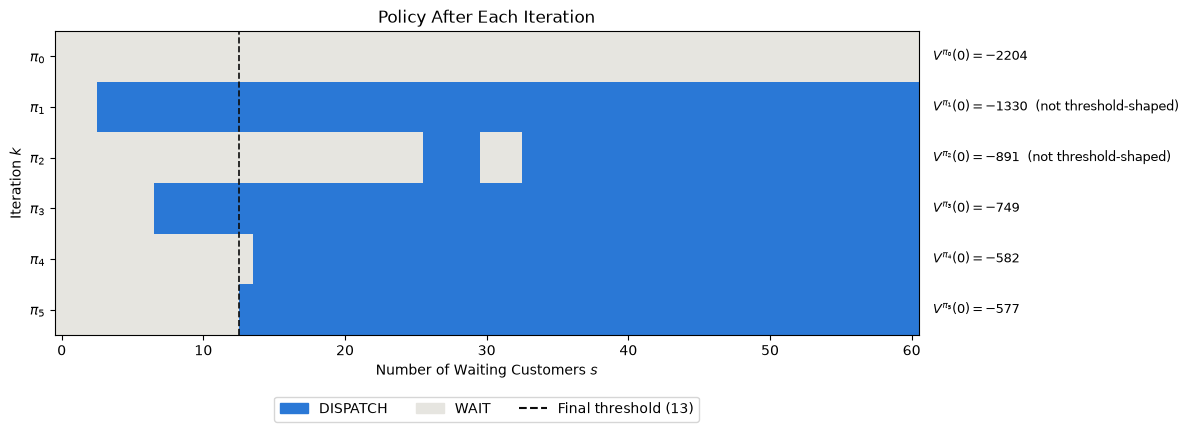

In [17]:
EVOLUTION_STATES = 60

policies = np.array(
    [to_dispatch(p) for p in pi_solver.policy_history]
)  # iteration x state
n_iterations = len(policies)

print(
    f"{'k':>2} {'first D':>8} {'threshold-shaped':>17} {'eval sweeps':>12} {'V(0)':>10}"
)
for k, (row, sweeps_k, V_k) in enumerate(
    zip(policies, pi_solver.evaluation_sweeps, pi_solver.value_history)
):
    f = first_dispatch(row)
    print(
        f"{k:>2} {'never' if np.isnan(f) else int(f):>8} {str(is_threshold_shaped(row)):>17} {sweeps_k:>12} {V_k[0]:>10.1f}"
    )

report(
    f"Converges in {n_iterations} policy evaluations to the threshold policy s >= {threshold}",
    first_dispatch(policies[-1]) == threshold and is_threshold_shaped(policies[-1]),
)
report(
    "Every iteration before the last changes the policy",
    all((policies[k] != policies[k + 1]).any() for k in range(n_iterations - 1)),
)

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.imshow(
    policies[:, : EVOLUTION_STATES + 1],
    aspect="auto",
    interpolation="nearest",
    cmap=ListedColormap([WAIT_GREY, BLUE]),
    vmin=0,
    vmax=1,
    extent=(-0.5, EVOLUTION_STATES + 0.5, n_iterations - 0.5, -0.5),
)
ax.axvline(threshold - 0.5, color=INK, linestyle="--", linewidth=1.2)
for k, V_k in enumerate(pi_solver.value_history):
    shape_note = "" if is_threshold_shaped(policies[k]) else "  (not threshold-shaped)"
    ax.text(
        EVOLUTION_STATES + 1.5,
        k,
        f"$V^{{\\pi_{k}}}(0) = {V_k[0]:.0f}${shape_note}",
        va="center",
        fontsize=9,
    )
ax.set(
    title="Policy After Each Iteration",
    xlabel="Number of Waiting Customers $s$",
    ylabel="Iteration $k$",
    yticks=range(n_iterations),
    yticklabels=[f"$\\pi_{k}$" for k in range(n_iterations)],
)
ax.legend(
    handles=[
        Patch(color=BLUE, label="DISPATCH"),
        Patch(color=WAIT_GREY, label="WAIT"),
        plt.Line2D(
            [], [], color=INK, linestyle="--", label=f"Final threshold ({threshold})"
        ),
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=3,
)
fig.tight_layout()
plt.show()

### Check 2: Policy Improvement Theorem
Acting greedily with respect to $V^{\pi_k}$ can never make things worse, so the theory guarantees

$$V^{\pi_{k+1}}(s) \geq V^{\pi_k}(s) \quad \text{for every state } s \text{ and every iteration } k,$$

with equality only once the policy is optimal. **Expected:** the value curves move up monotonically from iteration to iteration and end on $V^*$ from value iteration. Since policy evaluation stops at tolerance $\theta$, a violation smaller than the evaluation error $\gamma\theta/(1-\gamma)$ is allowed.

pi_0 -> pi_1: smallest change over all states = -1.8e-05
pi_1 -> pi_2: smallest change over all states = +1.6e+02
pi_2 -> pi_3: smallest change over all states = +1.1e+02
pi_3 -> pi_4: smallest change over all states = +7.9e+01
pi_4 -> pi_5: smallest change over all states = +2.5e+00
[PASS] V^(pi_k+1)(s) >= V^(pi_k)(s) for every state and iteration (up to the evaluation error 1.9e-05)


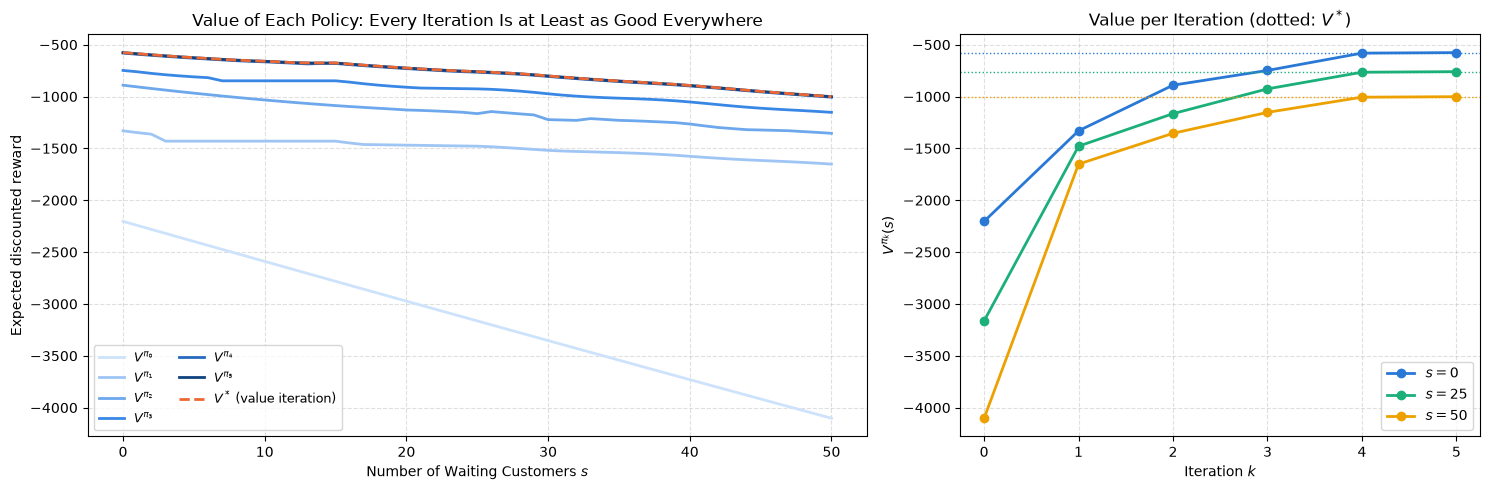

In [18]:
IMPROVEMENT_STATES = 50

value_history = np.array(pi_solver.value_history)
min_gain = np.diff(value_history, axis=0).min(
    axis=1
)  # Smallest improvement over all states

for k, gain in enumerate(min_gain):
    print(f"pi_{k} -> pi_{k + 1}: smallest change over all states = {gain:+.1e}")
report(
    f"V^(pi_k+1)(s) >= V^(pi_k)(s) for every state and iteration "
    f"(up to the evaluation error {evaluation_error_bound:.1e})",
    np.all(min_gain >= -2 * evaluation_error_bound),
)

fig, (ax_v, ax_s) = plt.subplots(1, 2, figsize=(15, 5), width_ratios=(1.5, 1))

shown = np.arange(IMPROVEMENT_STATES + 1)
ramp = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#104281"]
for k, V_k in enumerate(value_history):
    ax_v.plot(
        shown,
        V_k[shown],
        color=ramp[k % len(ramp)],
        linewidth=2,
        label=f"$V^{{\\pi_{k}}}$",
    )
ax_v.plot(
    shown,
    v_vi[shown],
    color=ORANGE,
    linewidth=2,
    linestyle="--",
    label="$V^*$ (value iteration)",
)
ax_v.set(
    title="Value of Each Policy: Every Iteration Is at Least as Good Everywhere",
    xlabel="Number of Waiting Customers $s$",
    ylabel="Expected discounted reward",
)
ax_v.legend(loc="lower left", ncol=2, fontsize=9)

for s, color in zip([0, 25, 50], [BLUE, AQUA, "#eda100"]):
    ax_s.plot(
        range(n_iterations),
        value_history[:, s],
        color=color,
        marker="o",
        linewidth=2,
        label=f"$s = {s}$",
    )
    ax_s.axhline(v_vi[s], color=color, linestyle=":", linewidth=1)
ax_s.set(
    title="Value per Iteration (dotted: $V^*$)",
    xlabel="Iteration $k$",
    ylabel="$V^{\\pi_k}(s)$",
    xticks=range(n_iterations),
)
ax_s.legend(loc="lower right")

for ax in (ax_v, ax_s):
    ax.grid(True, linestyle="--", alpha=0.4)

fig.tight_layout()
plt.show()

### Check 3: Agreement With Exact Evaluation and Value Iteration
Two independent references:
- **Exact policy evaluation:** for a fixed policy, the Bellman equation is linear, $V^\pi = r_\pi + \gamma P_\pi V^\pi$, so $V^\pi$ can be computed exactly by solving $(I - \gamma P_\pi) V = r_\pi$ (a $201 \times 201$ system). **Expected:** the iterative evaluation differs by at most $\gamma\theta/(1-\gamma)$.
- **Value iteration (2b):** **expected:** the same action in every state, and the same values up to the evaluation tolerance.

The right plot compares the effort of both algorithms, measured in sweeps over the whole state space.

[PASS] Same action as value iteration in all 201 states
[PASS] Iterative evaluation matches the exact linear solve: max error 1.86e-05 <= bound 1.90e-05
[PASS] V matches value iteration: max difference 1.87e-05


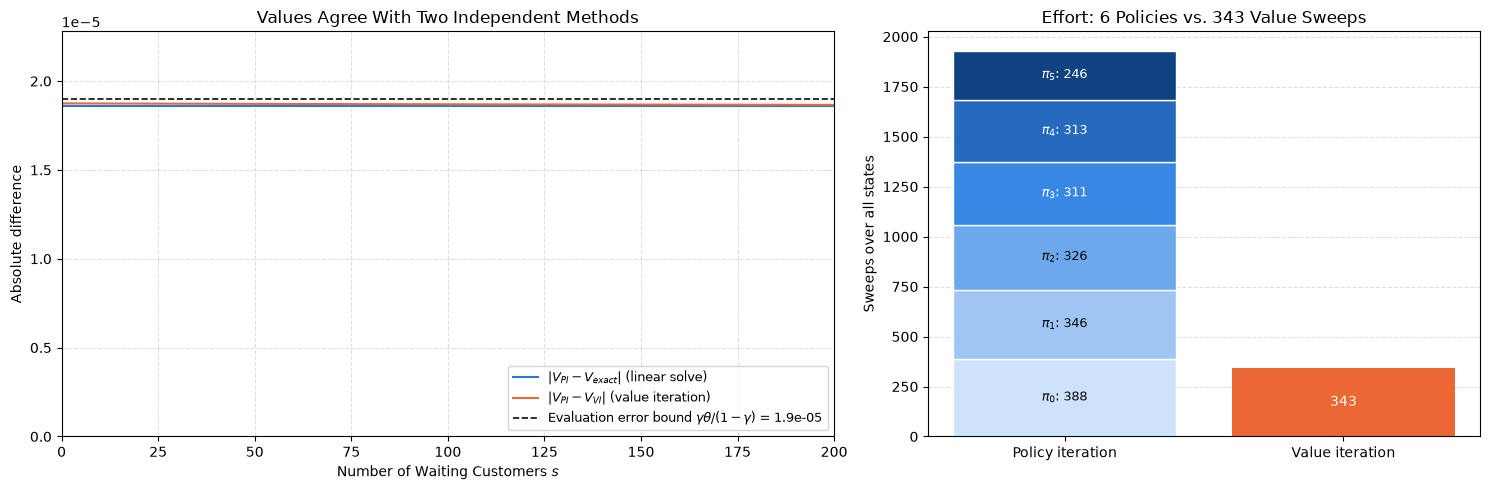

In [19]:
vi_dispatch = np.array([vi_solver.get_action(s) == D for s in states])

# Exact evaluation of the final policy: solve (I - gamma * P) V = r
P = np.zeros((MAX_STATE + 1, MAX_STATE + 1))
r = np.zeros(MAX_STATE + 1)
for s in states:
    for p, s_next, reward in shuttle_env.transitions(int(s), pi_solver.policy[s]):
        P[s, min(s_next, MAX_STATE)] += p
        r[s] += p * reward
v_exact = np.linalg.solve(np.eye(MAX_STATE + 1) - GAMMA * P, r)

error_exact = np.abs(v_pi - v_exact)
error_vi = np.abs(v_pi - v_vi)

report(
    f"Same action as value iteration in all {MAX_STATE + 1} states",
    np.array_equal(dispatch, vi_dispatch),
)
report(
    f"Iterative evaluation matches the exact linear solve: max error {error_exact.max():.2e} <= bound {evaluation_error_bound:.2e}",
    error_exact.max() <= evaluation_error_bound,
)
report(
    f"V matches value iteration: max difference {error_vi.max():.2e}",
    error_vi.max() <= evaluation_error_bound + 1e-6,
)

fig, (ax_err, ax_cost) = plt.subplots(1, 2, figsize=(15, 5), width_ratios=(1.4, 1))

# Left: per-state differences, all below the evaluation error bound
ax_err.plot(
    states,
    error_exact,
    color=BLUE,
    linewidth=1.5,
    label="$|V_{PI} - V_{exact}|$ (linear solve)",
)
ax_err.plot(
    states,
    error_vi,
    color=ORANGE,
    linewidth=1.5,
    label="$|V_{PI} - V_{VI}|$ (value iteration)",
)
ax_err.axhline(
    evaluation_error_bound,
    linestyle="--",
    color=INK,
    linewidth=1.2,
    label=f"Evaluation error bound $\\gamma\\theta / (1-\\gamma)$ = {evaluation_error_bound:.1e}",
)
ax_err.set(
    title="Values Agree With Two Independent Methods",
    xlabel="Number of Waiting Customers $s$",
    ylabel="Absolute difference",
    xlim=(0, MAX_STATE),
    ylim=(0, 1.2 * evaluation_error_bound),
)
ax_err.grid(True, linestyle="--", alpha=0.4)
ax_err.legend(loc="lower right", fontsize=9)

# Right: computational effort in sweeps over the state space
bottom = 0
eval_colors = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#104281"]
for k, sweeps_k in enumerate(pi_solver.evaluation_sweeps):
    ax_cost.bar(
        "Policy iteration",
        sweeps_k,
        bottom=bottom,
        color=eval_colors[k % len(eval_colors)],
        edgecolor="white",
    )
    ax_cost.text(
        0,
        bottom + sweeps_k / 2,
        f"$\\pi_{k}$: {sweeps_k}",
        ha="center",
        va="center",
        fontsize=9,
        color="white" if k >= 3 else INK,
    )
    bottom += sweeps_k
ax_cost.bar("Value iteration", len(vi_solver.deltas), color=ORANGE)
ax_cost.text(
    1,
    len(vi_solver.deltas) / 2,
    f"{len(vi_solver.deltas)}",
    ha="center",
    va="center",
    fontsize=10,
    color="white",
)
ax_cost.set(
    title=f"Effort: {len(pi_solver.policy_history)} Policies vs. {len(vi_solver.deltas)} Value Sweeps",
    ylabel="Sweeps over all states",
)
ax_cost.grid(True, axis="y", linestyle="--", alpha=0.4)
ax_cost.set_axisbelow(True)

fig.tight_layout()
plt.show()

### Check 4: Independence of the Initial Policy
The optimal policy is unique here, and policy iteration must find it from **any** starting point. I start from five very different policies: never dispatch (default), always dispatch, dispatch as soon as anyone waits, dispatch only at 30 or more, and a random policy. **Expected:** all runs end in the same policy as value iteration (threshold 13) after a handful of iterations.

initial policy               evaluations  sweeps   first dispatch state per iteration
All WAIT (default)                     6    1930   never -> 3 -> 26 -> 7 -> 14 -> 13
All DISPATCH                           5    1600   0 -> 45 -> 5 -> 14 -> 13
Dispatch if s >= 1                     5    1600   1 -> 45 -> 5 -> 14 -> 13
Dispatch if s >= 30                    4    1231   30 -> 7 -> 14 -> 13
Random (each state 50/50)              4    1236   1 -> 17 -> 11 -> 13
[PASS] Every initial policy converges to the same policy as value iteration (threshold 13)
[PASS] Every run needs at most 6 policy evaluations


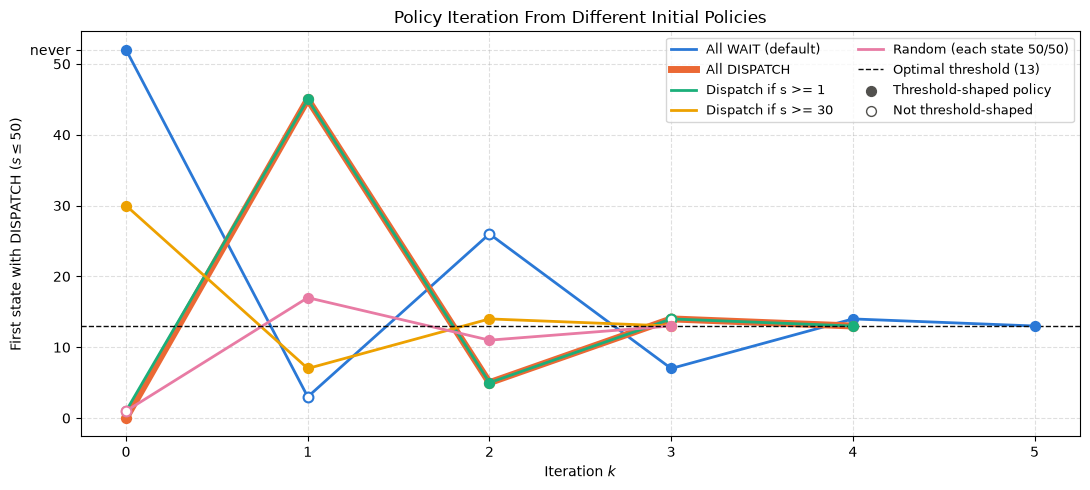

In [20]:
init_rng = np.random.default_rng(seed=0)
initial_policies = {
    "All WAIT (default)": [W] * (MAX_STATE + 1),
    "All DISPATCH": [D] * (MAX_STATE + 1),
    "Dispatch if s >= 1": [D if s >= 1 else W for s in states],
    "Dispatch if s >= 30": [D if s >= 30 else W for s in states],
    "Random (each state 50/50)": [
        D if u < 0.5 else W for u in init_rng.random(MAX_STATE + 1)
    ],
}
run_colors = [BLUE, ORANGE, AQUA, "#eda100", "#e87ba4"]
run_widths = [
    2,
    5,
    2,
    2,
    2,
]  # "All DISPATCH" is drawn thicker: it overlaps "Dispatch if s >= 1" after iteration 0
NEVER = 52  # Plot position for "never dispatches in s <= 50"

runs = {}
for name, initial_policy in initial_policies.items():
    solver = ShuttlePolicyIteration(
        env=shuttle_env,
        max_state=MAX_STATE,
        gamma=GAMMA,
        theta=THETA,
        initial_policy=initial_policy,
    )
    solver.solve()
    runs[name] = solver

print(
    f"{'initial policy':<28} {'evaluations':>11} {'sweeps':>7}   first dispatch state per iteration"
)
for name, solver in runs.items():
    firsts = [first_dispatch(p) for p in solver.policy_history]
    print(
        f"{name:<28} {len(solver.policy_history):>11} {sum(solver.evaluation_sweeps):>7}   "
        + " -> ".join("never" if np.isnan(f) else str(int(f)) for f in firsts)
    )

report(
    f"Every initial policy converges to the same policy as value iteration (threshold {threshold})",
    all(
        solver.policy == [vi_solver.get_action(s) for s in states]
        for solver in runs.values()
    ),
)
report(
    "Every run needs at most 6 policy evaluations",
    all(len(solver.policy_history) <= 6 for solver in runs.values()),
)

fig, ax = plt.subplots(figsize=(11, 5))
for (name, solver), color, width in zip(runs.items(), run_colors, run_widths):
    firsts = np.array([first_dispatch(p) for p in solver.policy_history])
    shaped = np.array([is_threshold_shaped(p) for p in solver.policy_history])
    y = np.where(np.isnan(firsts), NEVER, firsts)
    ax.plot(range(len(y)), y, color=color, linewidth=width, label=name)
    ax.scatter(np.flatnonzero(shaped), y[shaped], color=color, s=50, zorder=3)
    ax.scatter(
        np.flatnonzero(~shaped),
        y[~shaped],
        facecolor="white",
        edgecolor=color,
        linewidth=1.5,
        s=50,
        zorder=3,
    )

ax.axhline(
    threshold,
    linestyle="--",
    color=INK,
    linewidth=1,
    label=f"Optimal threshold ({threshold})",
)
ax.scatter([], [], color=MUTED, s=50, label="Threshold-shaped policy")
ax.scatter(
    [], [], facecolor="white", edgecolor=MUTED, s=50, label="Not threshold-shaped"
)
ax.set(
    title="Policy Iteration From Different Initial Policies",
    xlabel="Iteration $k$",
    ylabel="First state with DISPATCH ($s \\leq 50$)",
    xticks=range(max(len(s.policy_history) for s in runs.values())),
    yticks=[0, 10, 20, 30, 40, 50, NEVER],
    yticklabels=["0", "10", "20", "30", "40", "50", "never"],
)
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(loc="upper right", fontsize=9, ncol=2)
fig.tight_layout()
plt.show()

### Edge-Case Checks
- **Invalid inputs:** $\gamma \notin [0, 1)$ and an initial policy that does not cover every state are rejected with a `ValueError`.
- **Ties:** with $c_f = c_h = 0$ every action costs nothing, so all Q-values are equal. The solver only switches an action for an improvement larger than the evaluation error, so it must keep the initial policy and stop after one evaluation instead of switching back and forth.
- **Iteration limit:** policy iteration always terminates in theory (there are finitely many policies), but a bug or numerical noise could make it cycle. `max_iterations` turns that into an error instead of an endless loop.
- **Cap at 200:** as in 2b, doubling the cap must not change the policy or the values on $s \leq 50$.

In [21]:
LARGER_MAX_STATE = 400

# Invalid inputs are rejected
for invalid_gamma in (1.0, 1.5, -0.1):
    try:
        ShuttlePolicyIteration(
            env=shuttle_env, max_state=MAX_STATE, gamma=invalid_gamma
        )
        report(f"gamma = {invalid_gamma} is rejected", False)
    except ValueError:
        report(f"gamma = {invalid_gamma} is rejected", True)

try:
    ShuttlePolicyIteration(
        env=shuttle_env, max_state=MAX_STATE, gamma=GAMMA, initial_policy=[W] * 10
    )
    report("Initial policy with the wrong number of states is rejected", False)
except ValueError:
    report("Initial policy with the wrong number of states is rejected", True)

# Every action ties: with c_f = c_h = 0 all Q-values are 0, so the initial policy must be kept
free_env = ShuttleEnvironment(
    shuttle_capacity=SHUTTLE_CAPACITY,
    shuttle_dispatch_cost=0,
    customer_waiting_cost=0,
    customer_arriving_options=CUSTOMER_ARRIVING_OPTIONS,
    customer_arriving_probabilities=CUSTOMER_ARRIVING_PROBABILITIES,
)
tie_solver = ShuttlePolicyIteration(env=free_env, max_state=MAX_STATE, gamma=GAMMA)
tie_solver.solve()
report(
    f"All actions tie (c_f = c_h = 0): stops after {len(tie_solver.policy_history)} evaluation, "
    f"keeps the initial policy, V = 0",
    len(tie_solver.policy_history) == 1
    and tie_solver.policy == tie_solver.initial_policy
    and np.allclose(tie_solver.V, 0),
)

# The iteration limit stops a run that has not converged instead of looping forever
try:
    ShuttlePolicyIteration(
        env=shuttle_env, max_state=MAX_STATE, gamma=GAMMA, max_iterations=2
    ).solve()
    report("Iteration limit raises an error when it is reached", False)
except RuntimeError:
    report("Iteration limit raises an error when it is reached", True)

# The cap at 200 does not influence the states that occur
larger_solver = ShuttlePolicyIteration(
    env=shuttle_env, max_state=LARGER_MAX_STATE, gamma=GAMMA, theta=THETA
)
larger_solver.solve()
cap_difference = np.abs(np.array(larger_solver.V[:51]) - v_pi[:51]).max()
report(
    f"Cap {MAX_STATE} vs. {LARGER_MAX_STATE}: same policy and V on s <= 50 (max difference {cap_difference:.1e})",
    larger_solver.policy[:51] == pi_solver.policy[:51]
    and cap_difference < 2 * evaluation_error_bound,
)

[PASS] gamma = 1.0 is rejected
[PASS] gamma = 1.5 is rejected
[PASS] gamma = -0.1 is rejected
[PASS] Initial policy with the wrong number of states is rejected
[PASS] All actions tie (c_f = c_h = 0): stops after 1 evaluation, keeps the initial policy, V = 0
[PASS] Iteration limit raises an error when it is reached
[PASS] Cap 200 vs. 400: same policy and V on s <= 50 (max difference 0.0e+00)
